# Лабораторная работа 1. Очистка набора данных и отбор признаков

Цель - провести очистку набора данных и отобрать признаки.

1. Целевые параметры G-total и КГФ (их два, но отличаются они только единицей измерения, поэтому объединить оба КГФ в один столбец)

Удалить строки, где обе целевых переменные пустые (и g-total и кгф)

Пропуски заполнить NaN

Сохранить названия признаков

Построить гистраграмму важности признаков по критерию gain_ratio (нормированный прирост информации)

Построить тепловую карту признаков (матрица корреляций всех признаков со всеми, в том числе целевыми переменными), для удобства коэффициент корреляции берите по модулю

Для каждого признака построить график распределения с отложенными на нем линиями первого и третьего квартилей

Для каждого признака посчитать элементы описательной статистики

На основании всего этого и рекомендаций по работе с признаками из лекции составить список удаляемых и оставляемых признаков с обоснованием почему Вы это сделали.

Борьба с выбросами и заполнение пропусков остается на усмотрение студента, но должна быть обоснована и проводится только после расчета корреляций и важности.

Нормализация в данной лабораторной не предполагается.



2. Пользуясь материалами лекции 1 заполнить пропуски, там где это можно, удалить лишние признаки. Для этого Вам понадобится весь инструментарий:

а) распределения значений признаков, чтобы убрать выбросы и определить чем заполнять пропуски

б) описательная статистика, чтобы убрать признаки с большим количеством пропуском и малым количеством уникальных значений, а также заполнить пропуски

в) тепловая карта признаков (она же матрица корреляций), чтобы убрать мультиколлинеарность

г) гистограмма важности признаков по критерию gain_ratio (можно использовать вектор признаков, выгруженный из random forest, в этом случае можно взять параметр mutual-ratio)

## 1. Загрузка и первичный осмотр

In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mutual_info_score
from sklearn.ensemble import RandomForestRegressor
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = "1. Data.xlsx"
df_raw = pd.read_excel(DATA_PATH, sheet_name="VU")
df = df_raw.copy()
df.columns = df.columns.astype(str).str.strip()
df = df.replace(r"^\s*$", np.nan, regex=True)

targets = ["G_total", "КГФ"]
features = [col for col in df.columns if col not in targets]

print(f"Размер исходного набора: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("Целевые переменные:", targets)
print("Признаки:", len(features))
display(df.head())
display(df.info())

Размер исходного набора: 93 строк, 30 столбцов
Целевые переменные: ['G_total', 'КГФ']
Признаки: 28


,Глубина манометра,Dшт,Руст(ср),Рзаб(ср),Pлин(ср),Руст(кон),Рзаб(кон),Рлин(кон),Туст,Тна шлейфе,Тзаб,Tлин,Дебит газа(ст),Дебит ст. конд.(ст),Дебит воды(ст),Дебит смеси(ст),Дебит газа(лин),Дебит кон нестабильный(лин),Дебит воды(лин),Нэф,Рпл. Тек (послед точка на КВД),Рпл. Тек (Расчет по КВД),Рпл. Тек (Карноухов),Pсб,Ro_g,Ro_c,Ro_w,Удельная плотность газа,G_total,КГФ
0,3576.3,7.94,249.6,370.1,101.8,249.0,359.6,101.8,53.0,31.7,103.2,32.5,214.704,83.6,0.4,231.24884,1610.368866,131.3,0.4,56.8,45.25,56.5,NaN,93.6,0.806017,801.0,1000.0,0.669449,2.782623,311.9094
1,3576.3,9.53,233.5,364.6,101.3,249.0,338.1,102.4,58.8,37.6,103.0,38.6,290.594,104.7,1.4,309.00166,2310.226429,158.5,1.4,56.8,45.25,56.5,NaN,92.9,0.806017,801.0,1000.0,0.669449,3.697781,288.6003
2,3576.3,11.11,213.4,357.1,101.6,211.0,314.8,100.6,63.6,42.8,102.6,43.4,368.042,114.3,1.9,388.11498,3039.489680,172.3,1.9,56.8,45.25,56.5,NaN,91.4,0.806017,801.0,1000.0,0.669449,4.515073,248.7906
3,3576.3,12.70,191.6,347.4,98.4,187.0,291.5,99.0,64.7,46.2,102.0,46.1,434.663,121.3,3.3,455.21452,3824.082686,181.5,3.3,56.8,45.25,56.5,NaN,89.2,0.806017,801.0,1000.0,0.669449,5.217673,223.5591
4,3576.3,14.29,171.9,337.7,99.2,169.0,270.3,99.5,64.0,49.4,104.4,49.9,483.283,129.8,4.6,504.58778,4299.104676,190.6,4.7,56.8,45.25,56.5,NaN,89.7,0.806017,801.0,1000.0,0.669449,5.765092,215.1486


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Глубина манометра               90 non-null     float64
 1   Dшт                             93 non-null     float64
 2   Руст(ср)                        93 non-null     float64
 3   Рзаб(ср)                        90 non-null     float64
 4   Pлин(ср)                        93 non-null     float64
 5   Руст(кон)                       93 non-null     float64
 6   Рзаб(кон)                       90 non-null     float64
 7   Рлин(кон)                       93 non-null     float64
 8   Туст                            93 non-null     float64
 9   Тна шлейфе                      60 non-null     float64
 10  Тзаб                            90 non-null     float64
 11  Tлин                            93 non-null     float64
 12  Дебит газа(ст)                  93 non

None

Пустые ячейки приведены к NaN, а строки удаляются только тогда, когда одновременно отсутствуют обе целевые переменные.

In [13]:
rows_before = len(df)
df = df.dropna(subset=targets, how="all").copy()
print(f"Удалено строк без обеих целевых переменных: {rows_before - len(df)}")
print("Число наблюдений с известными значениями целей:")
display(df[targets].notna().sum().rename("Количество"))

Удалено строк без обеих целевых переменных: 0
Число наблюдений с известными значениями целей:


,Количество
G_total,23
КГФ,93


## 2. Описательная статистика

In [14]:
def descriptive_statistics(data):
    result = pd.DataFrame(index=data.columns)
    result["Количество"] = data.count()
    result["Процент пропусков"] = data.isna().mean() * 100
    result["Минимум"] = data.min()
    result["Первый квартиль"] = data.quantile(0.25)
    result["Среднее"] = data.mean()
    result["Медиана"] = data.median()
    result["Третий квартиль"] = data.quantile(0.75)
    result["Максимум"] = data.max()
    result["Стандартное отклонение"] = data.std()
    result["Мощность"] = data.nunique(dropna=True)
    result["Интерквартильный размах"] = result["Третий квартиль"] - result["Первый квартиль"]
    return result

stats = descriptive_statistics(df)
display(stats.style.format({"Процент пропусков": "{:.1f}%"}))

,Количество,Процент пропусков,Минимум,Первый квартиль,Среднее,Медиана,Третий квартиль,Максимум,Стандартное отклонение,Мощность,Интерквартильный размах
Глубина манометра,90,3.2%,3276.000000,3427.625000,3524.086667,3579.000000,3652.250000,3670.000000,144.474862,20,224.625000
Dшт,93,0.0%,6.350000,9.530000,10.951183,11.110000,12.700000,15.880000,2.423172,10,3.170000
Руст(ср),93,0.0%,138.157895,201.636750,228.293412,229.894737,252.000000,337.108108,41.897238,87,50.363250
Рзаб(ср),90,3.2%,174.000000,297.797500,331.762255,337.789172,364.150000,458.600000,56.481235,88,66.352500
Pлин(ср),93,0.0%,73.306638,95.945951,99.860962,100.800000,103.865199,121.682930,7.300663,91,7.919248
Руст(кон),93,0.0%,136.000000,200.000000,227.837817,228.000000,252.000000,333.000000,41.814527,72,52.000000
Рзаб(кон),90,3.2%,174.000000,294.625000,330.334444,334.250000,362.150000,458.500000,56.357493,89,67.525000
Рлин(кон),93,0.0%,40.739839,95.335032,98.005453,100.260000,104.000000,123.616800,12.425851,88,8.664968
Туст,93,0.0%,24.200000,50.300000,56.172043,58.000000,64.000000,75.000000,11.250781,51,13.700000
Тна шлейфе,60,35.5%,14.000000,33.300000,43.091667,38.700000,46.375000,110.200000,19.602337,57,13.075000


Признаки с мощностью 1 не несут полезной информации, поэтому удаляются. При доле пропусков выше 60% признак рекомендуется игнорировать.

Пропуски не заполняются нулями; восстановления значений для признаков, у которых пропусков больше 30% нет

## 3. Корреляционная матрица

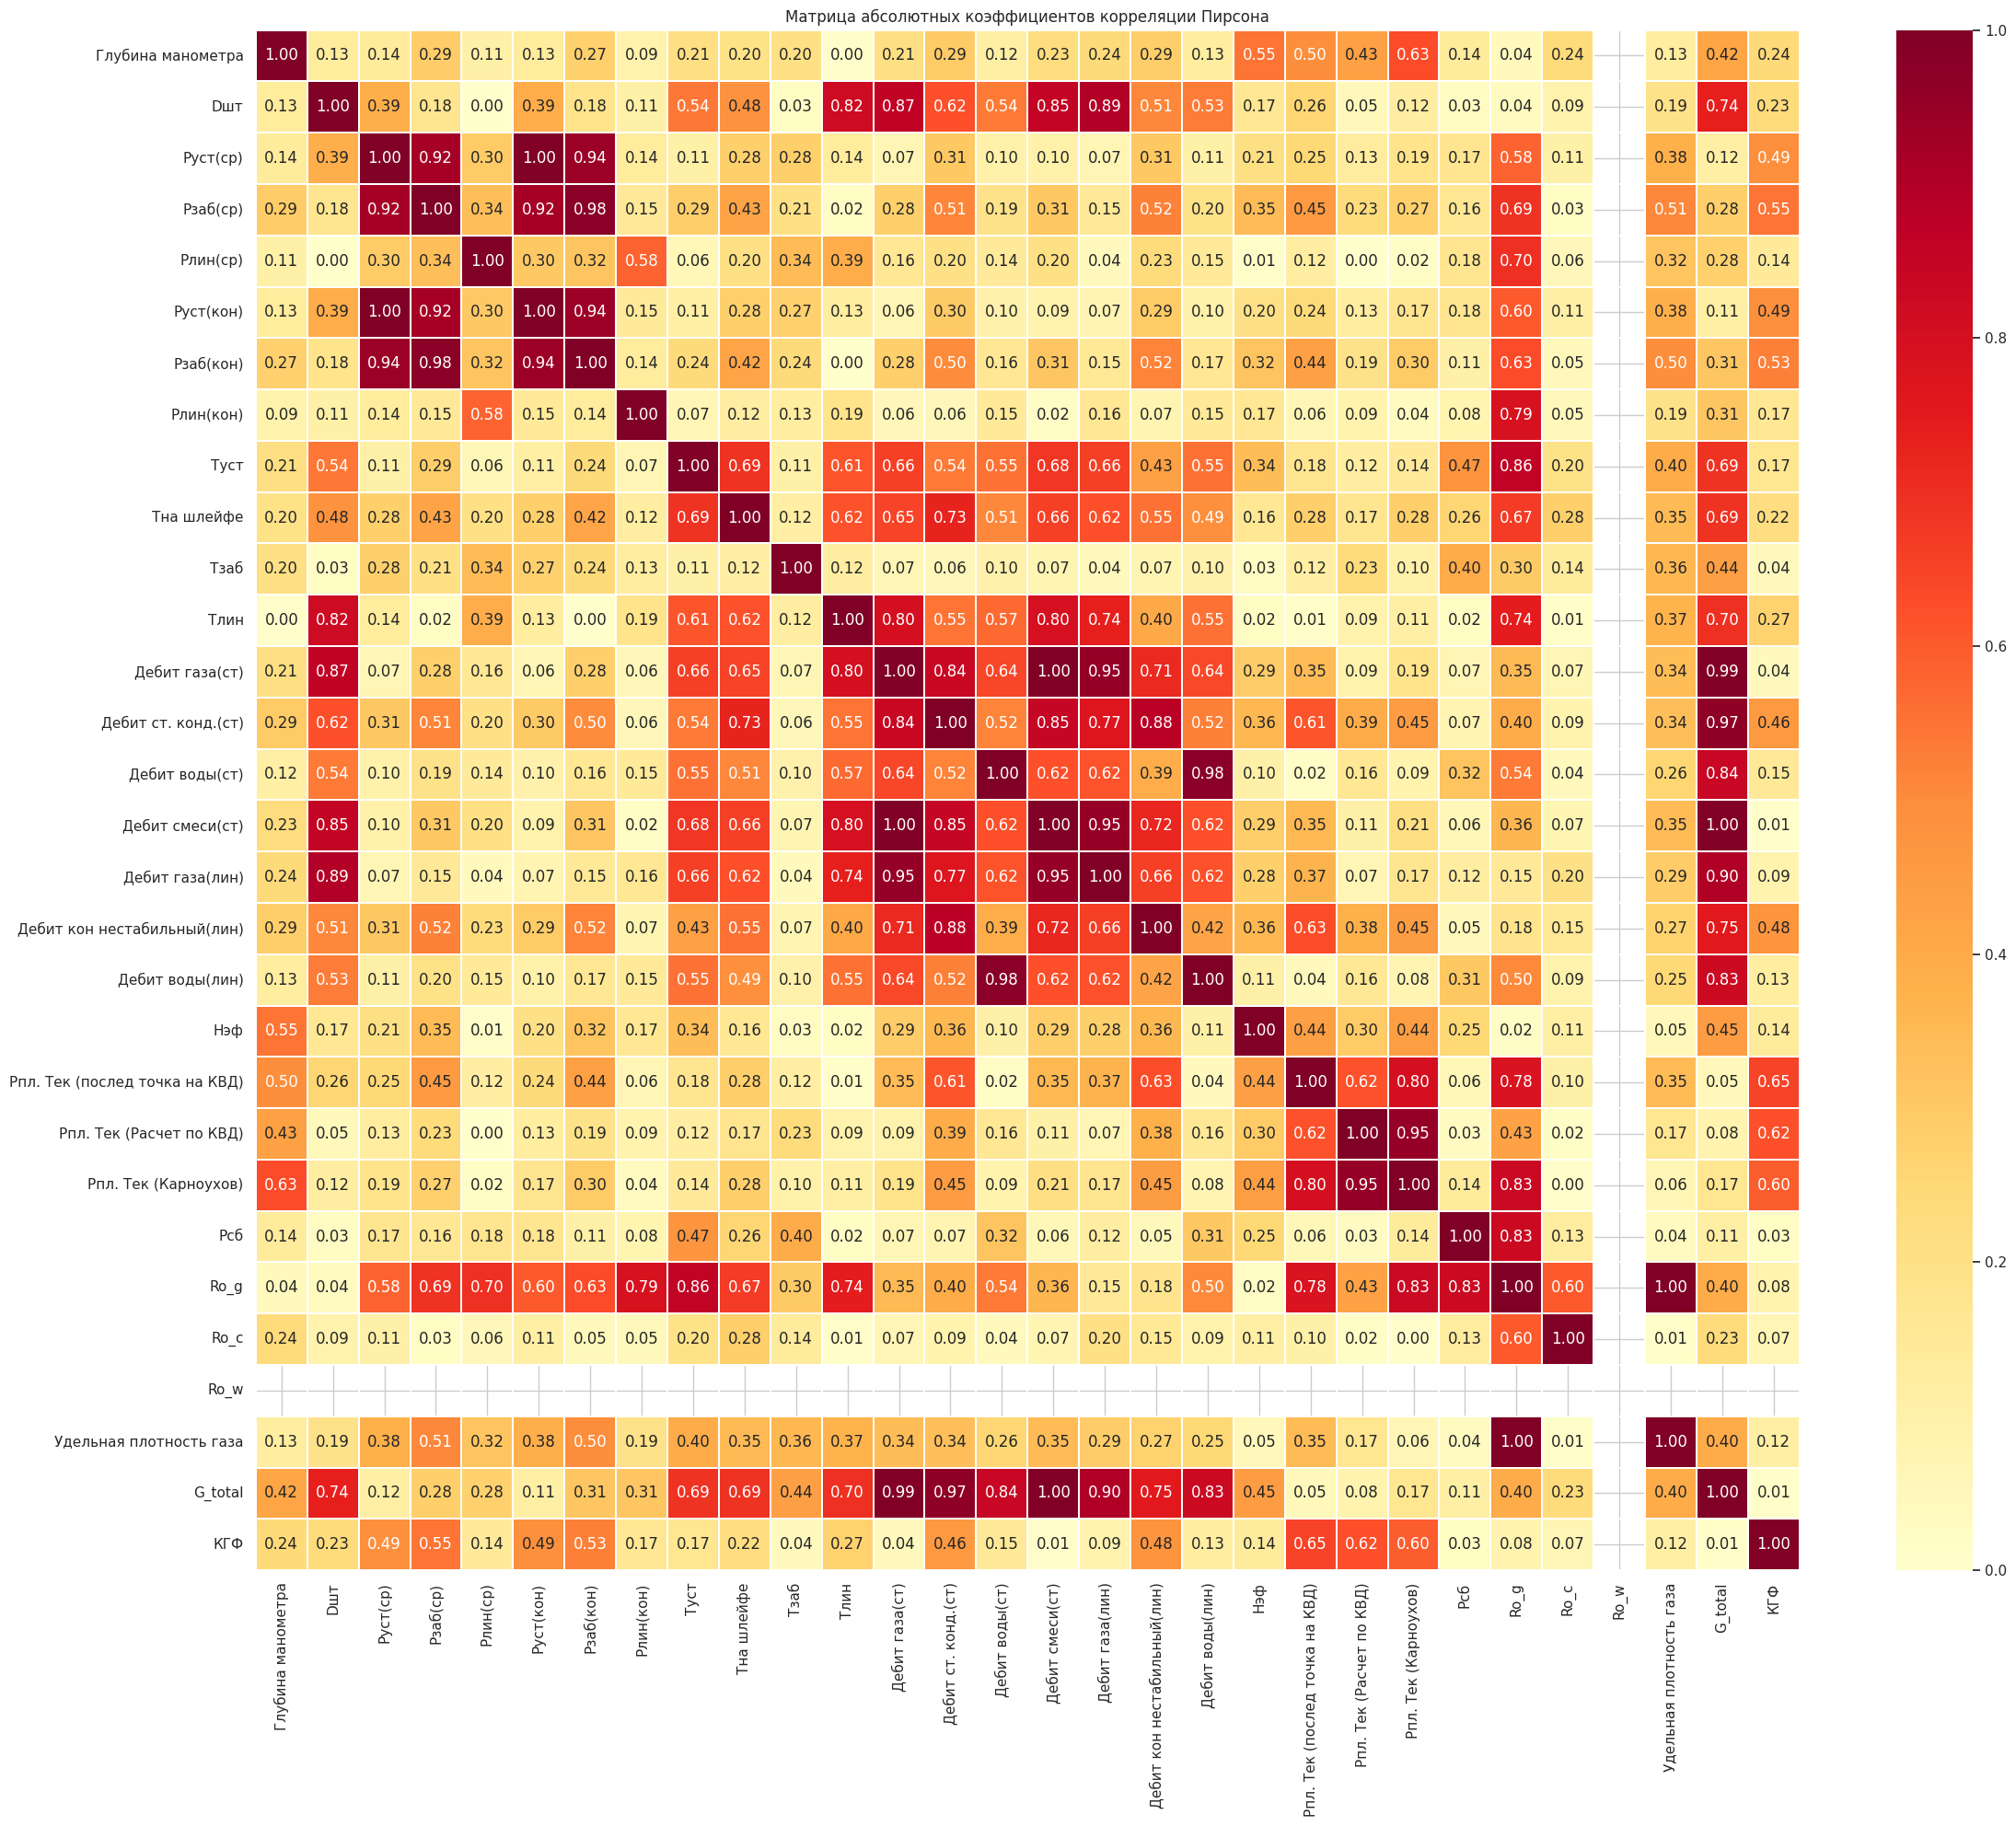

,G_total,КГФ
Рпл. Тек (послед точка на КВД),0.051377,0.648960
Рпл. Тек (Расчет по КВД),0.083467,0.624269
Рпл. Тек (Карноухов),0.170522,0.596974
Рзаб(ср),0.282975,0.548383
Рзаб(кон),0.311310,0.525020
Руст(ср),0.115329,0.494718
Руст(кон),0.112472,0.488682
Дебит кон нестабильный(лин),0.750067,0.475444
Дебит ст. конд.(ст),0.966527,0.458866
Tлин,0.698988,0.270998


,Признак 1,Признак 2,Корреляция
11,Ro_g,Удельная плотность газа,1.000000
6,Дебит газа(ст),Дебит смеси(ст),0.999025
1,Руст(ср),Руст(кон),0.998498
4,Рзаб(ср),Рзаб(кон),0.977898
8,Дебит воды(ст),Дебит воды(лин),0.975415
7,Дебит газа(ст),Дебит газа(лин),0.954222
10,Рпл. Тек (Расчет по КВД),Рпл. Тек (Карноухов),0.950151
9,Дебит смеси(ст),Дебит газа(лин),0.949442
2,Руст(ср),Рзаб(кон),0.941969
5,Руст(кон),Рзаб(кон),0.940245


In [15]:
corr = df[features + targets].corr(method="pearson")
plt.figure(figsize=(24, 20))
sns.heatmap(corr.abs(), cmap="YlOrRd", vmin=0, vmax=1, annot=True, fmt=".2f", linewidths=0.25)
plt.title("Матрица абсолютных коэффициентов корреляции Пирсона")
plt.tight_layout()
plt.show()

target_corr = corr[targets].abs().drop(index=targets)
display(target_corr.sort_values("КГФ", ascending=False))

pairs = []
for i, col_a in enumerate(features):
    for col_b in features[i + 1:]:
        value = corr.loc[col_a, col_b]
        if pd.notna(value) and abs(value) >= 0.90:
            pairs.append((col_a, col_b, value))
high_corr = pd.DataFrame(pairs, columns=["Признак 1", "Признак 2", "Корреляция"])
display(high_corr.sort_values("Корреляция", key=lambda x: x.abs(), ascending=False))

## 4. Распределения признаков и квартильные границы

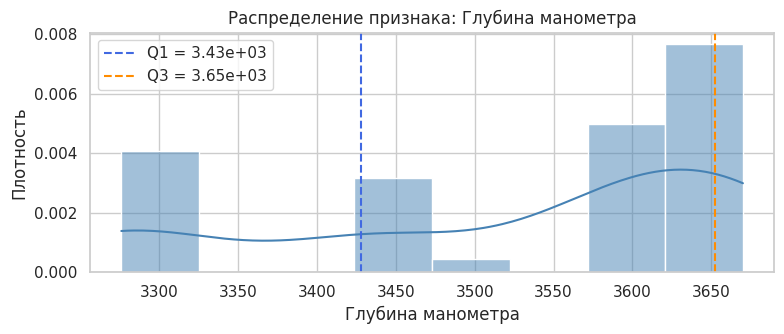

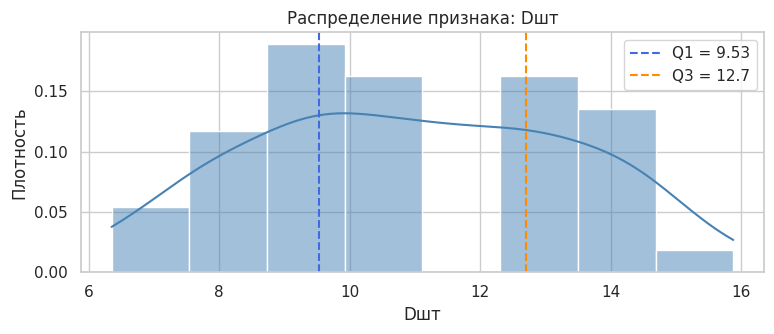

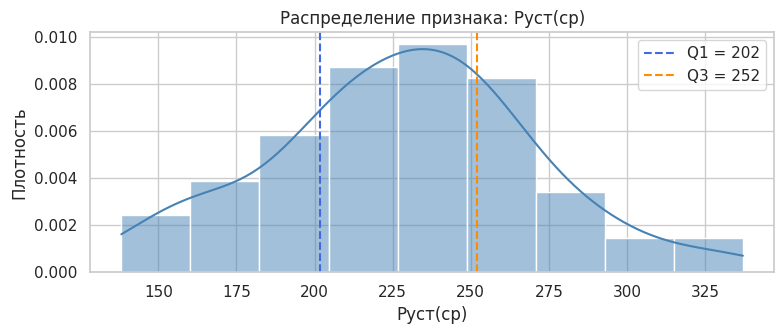

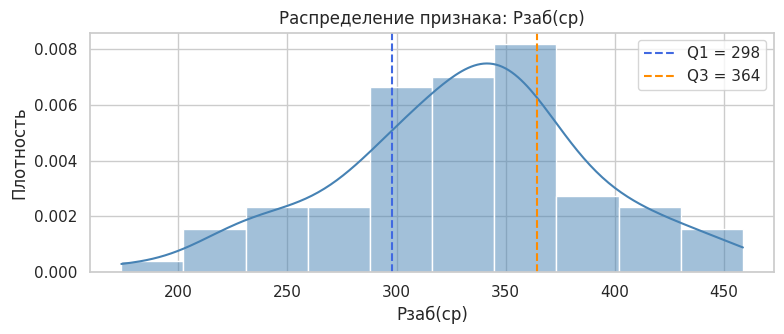

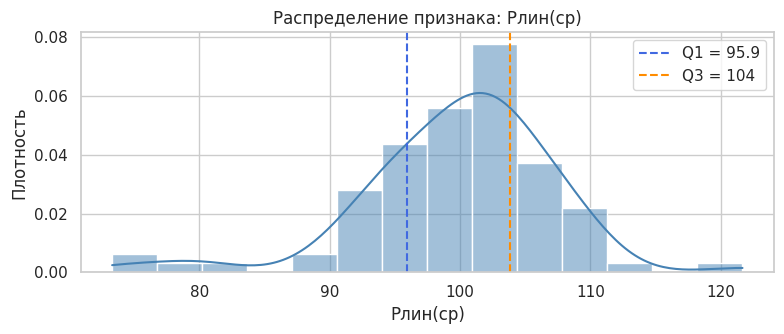

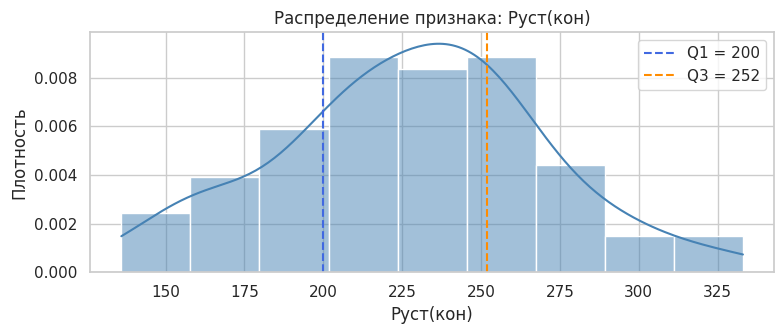

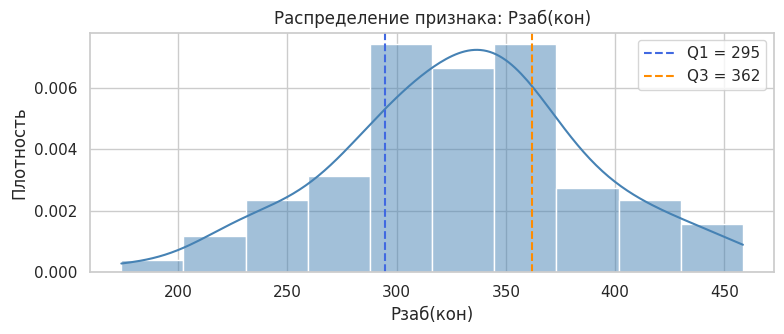

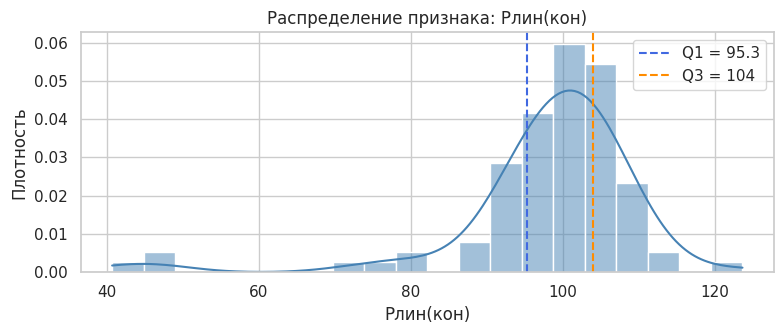

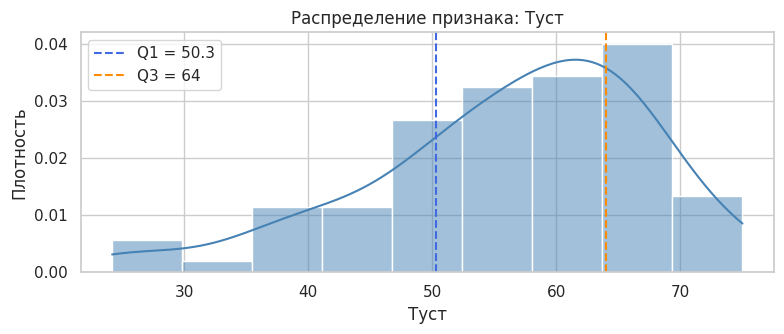

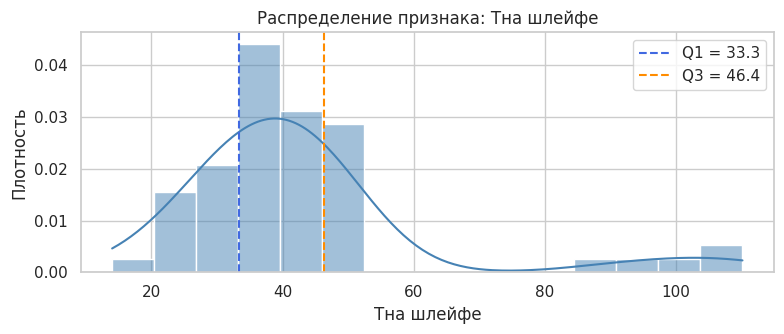

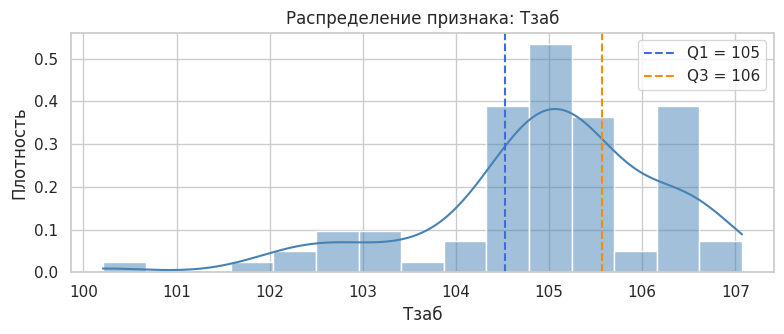

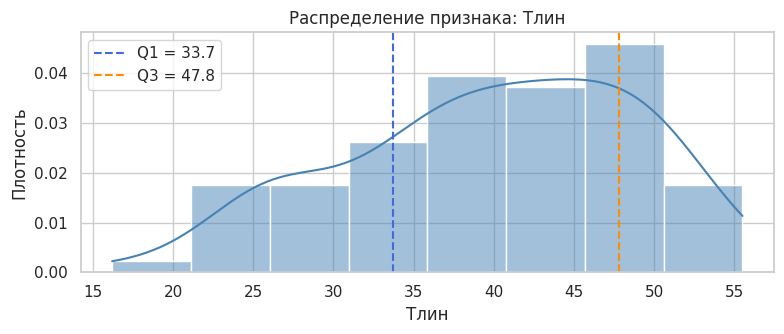

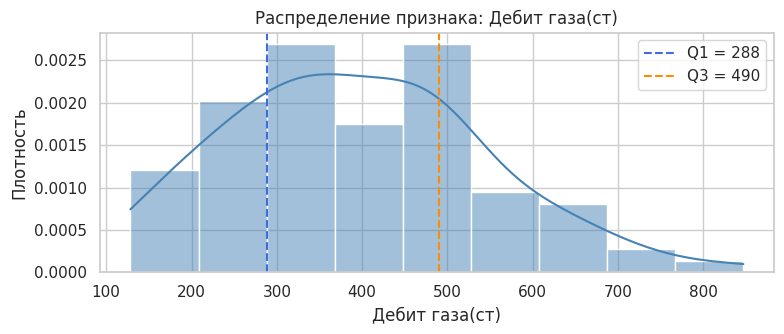

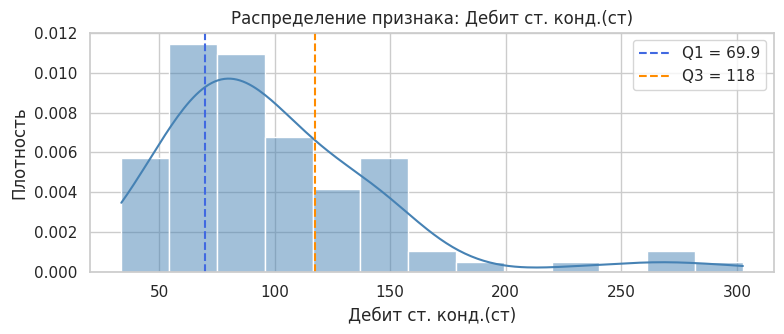

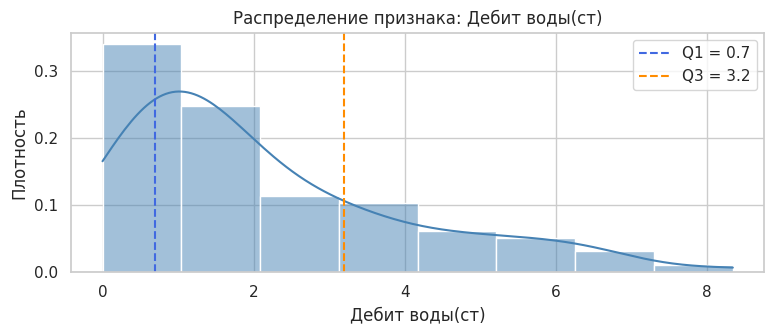

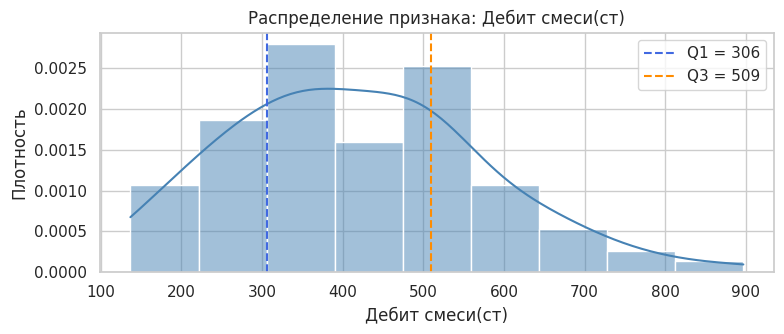

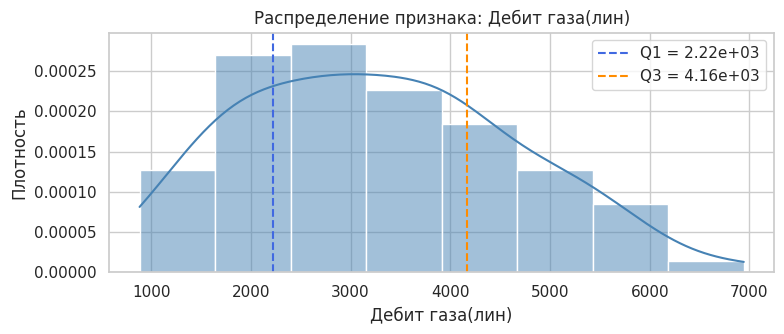

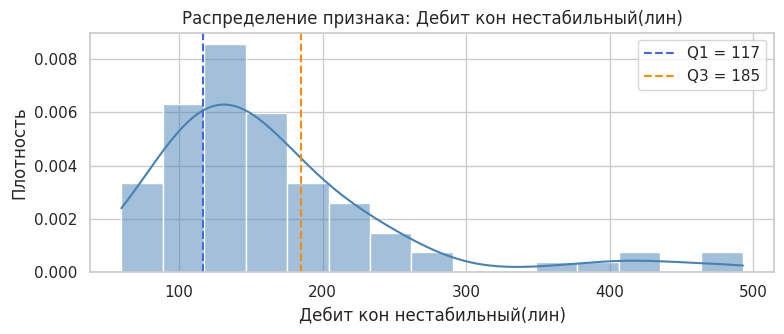

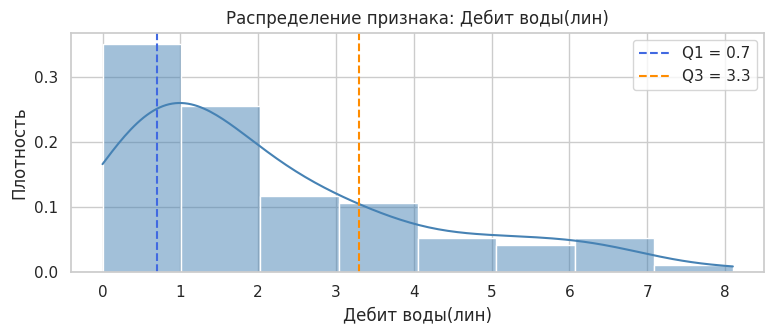

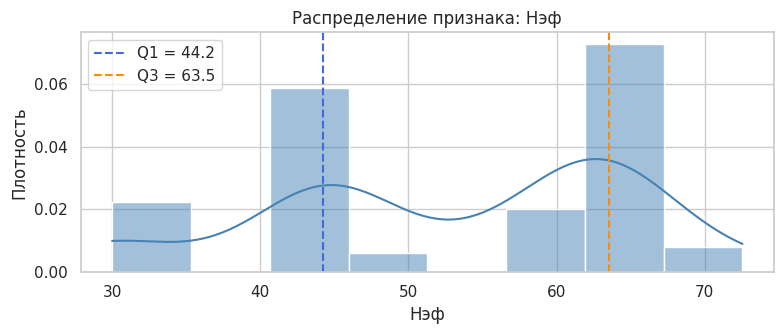

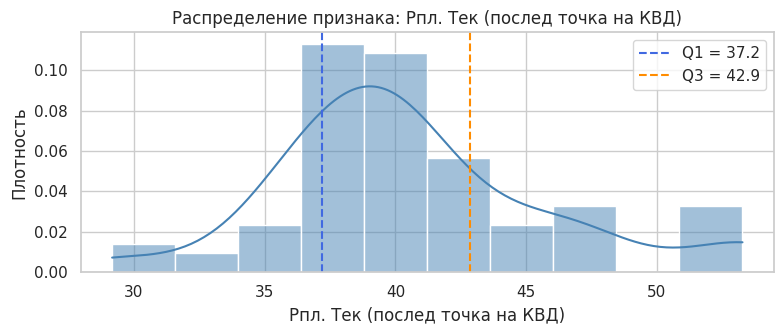

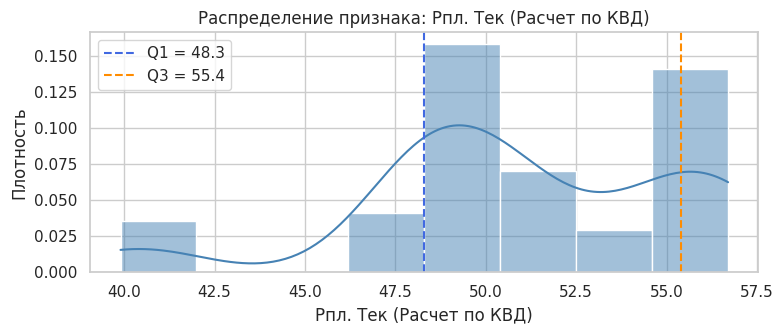

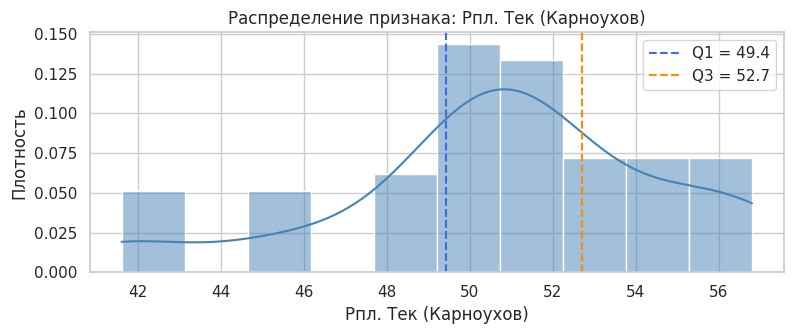

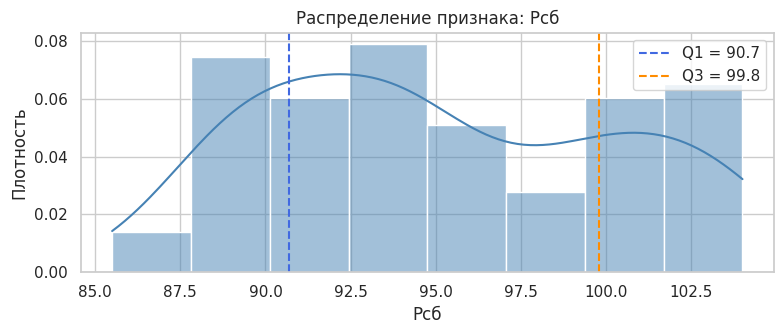

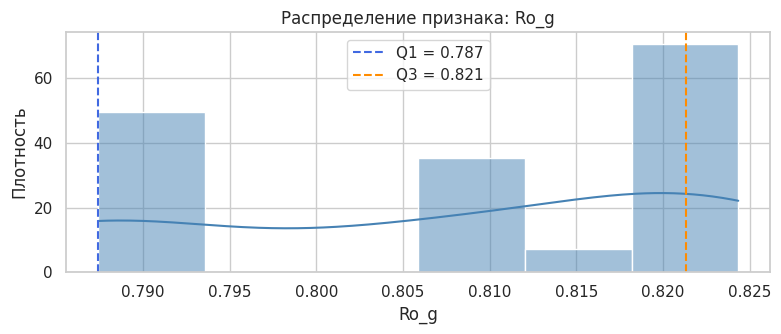

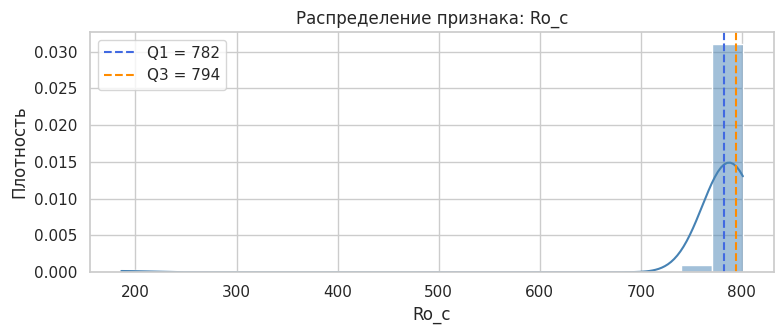

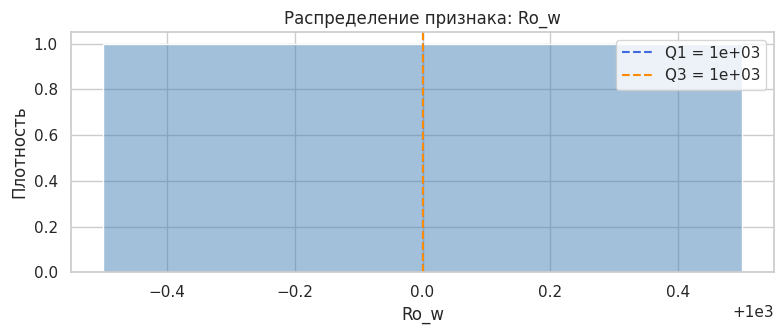

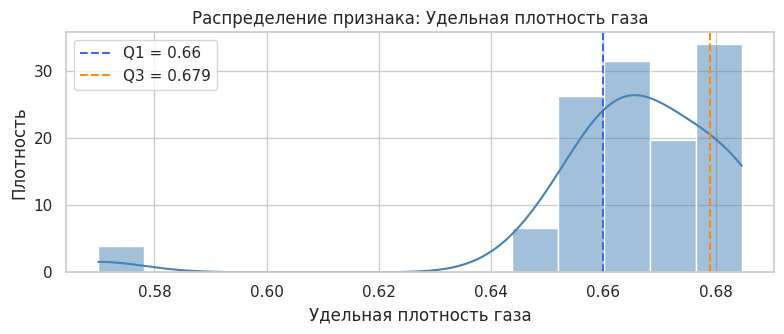

In [16]:
for col in features:
    values = df[col].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    plt.figure(figsize=(8, 3.5))
    sns.histplot(values, kde=True, stat="density", bins="auto", color="steelblue")
    plt.axvline(q1, color="royalblue", linestyle="--", label=f"Q1 = {q1:.3g}")
    plt.axvline(q3, color="darkorange", linestyle="--", label=f"Q3 = {q3:.3g}")
    plt.title(f"Распределение признака: {col}")
    plt.xlabel(col)
    plt.ylabel("Плотность")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 5. Важность признаков: Gain Ratio

,G_total,КГФ
Рпл. Тек (Карноухов),0.572994,0.318859
Рпл. Тек (Расчет по КВД),0.238422,0.237266
Ro_c,0.237931,0.234868
Рпл. Тек (послед точка на КВД),0.400803,0.231405
Глубина манометра,0.343351,0.218234
Ro_g,0.339299,0.215336
Рзаб(ср),0.362045,0.168505
Рзаб(кон),0.455483,0.156105
Тна шлейфе,0.404198,0.155589
Нэф,0.000000,0.152065


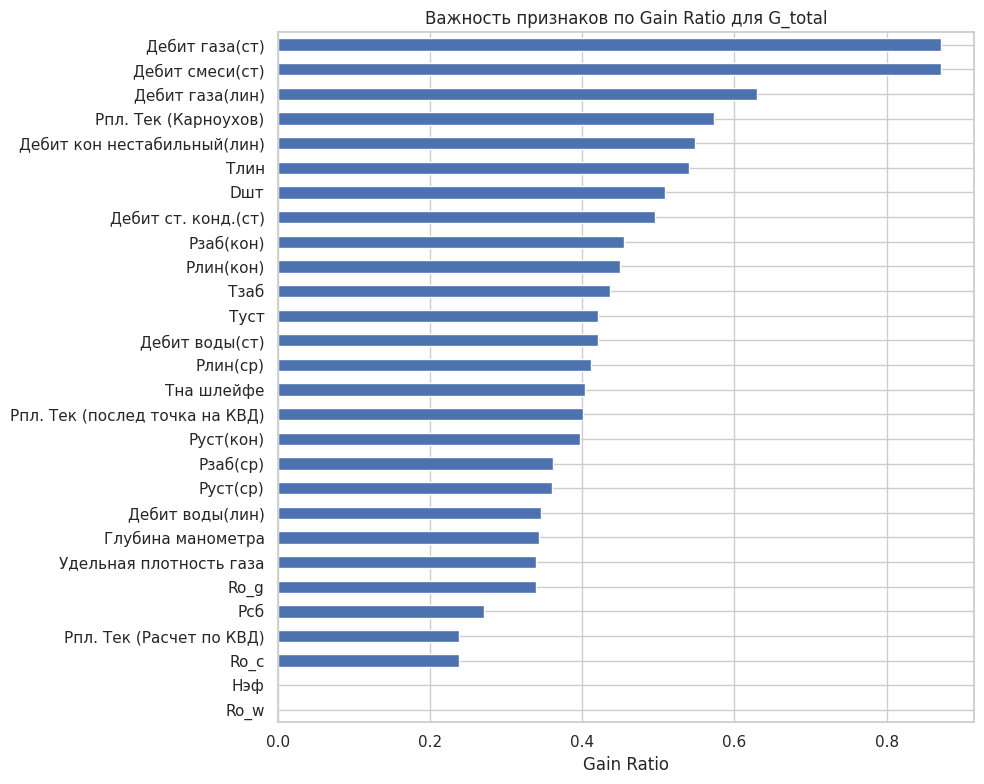

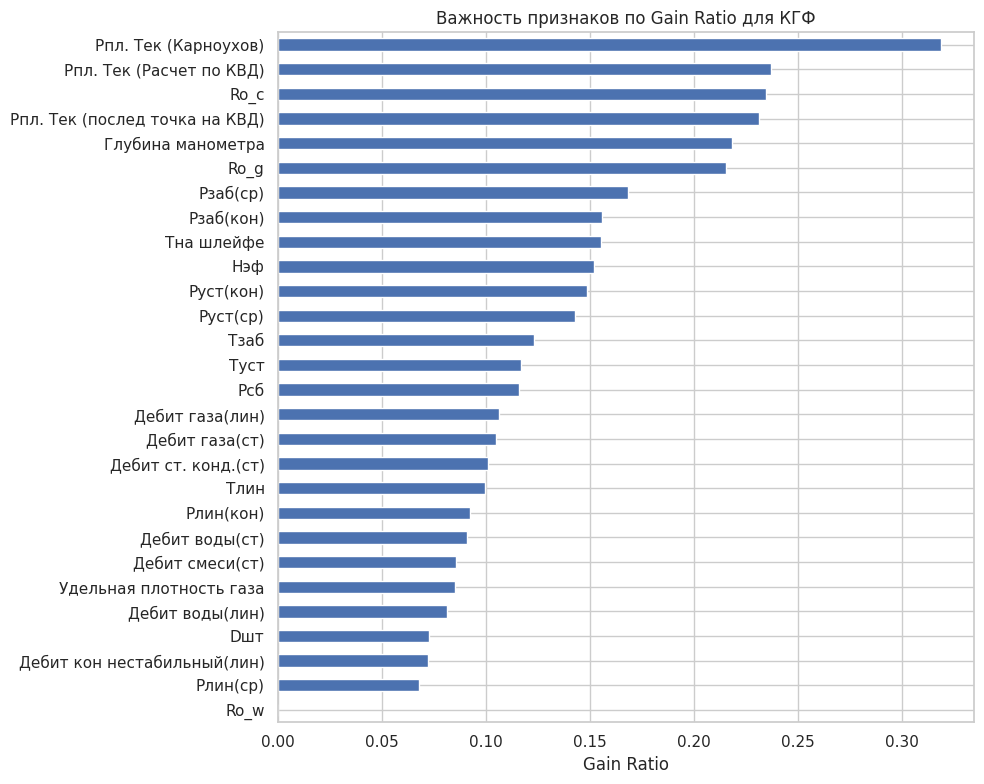

In [17]:
def gain_ratio_feature(x, y, bins=5):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(pair) < 5 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return 0.0
    x_bins = pd.qcut(pair["x"], q=min(bins, pair["x"].nunique()), labels=False, duplicates="drop")
    y_bins = pd.qcut(pair["y"], q=min(bins, pair["y"].nunique()), labels=False, duplicates="drop")
    x_bins = pd.Series(x_bins, index=pair.index).fillna(-1).astype(int)
    y_bins = pd.Series(y_bins, index=pair.index).fillna(-1).astype(int)
    information_gain = mutual_info_score(x_bins, y_bins)
    probabilities = x_bins.value_counts(normalize=True).to_numpy()
    split_information = -(probabilities * np.log(probabilities)).sum()
    return information_gain / split_information if split_information > 0 else 0.0

gain_ratio = pd.DataFrame(index=features)
for target in targets:
    gain_ratio[target] = [gain_ratio_feature(df[col], df[target]) for col in features]

display(gain_ratio.sort_values("КГФ", ascending=False))
for target in targets:
    plt.figure(figsize=(10, 8))
    gain_ratio[target].sort_values().plot(kind="barh")
    plt.title(f"Важность признаков по Gain Ratio для {target}")
    plt.xlabel("Gain Ratio")
    plt.tight_layout()
    plt.show()

Рассчитываем отдельно для каждой целевой переменной, также непрерывные значения предварительно разбиты на квантильные интервалы. Наличие пропусков учитывается попарным исключением наблюдений при расчёте конкретной пары признака и цели.

## 6. Обоснование отбора признаков

### Удаленные признаки:

1. `Ro_w`  Мощность равна 1 и 75,3% пропусков; - признак с одним уникальным значением неинформативен.
2. `Ro_g` Имеет 75,3% пропусков > 60% + коррелирует с `Удельная плотность газа`.
3. `Руст(кон)` Корреляция с `Руст(ср)` 0,99.
4. `Рзаб(кон)` Корреляция с `Рзаб(ср)` 0,97.
5. `Рпл. Тек (Карноухов)` 31,2% пропусков,+ коррелирует с `Рпл. Тек (Расчет по КВД)`
6. `Рпл. Тек (послед точка на КВД)` как вариант с меньшей долей пропусков и наибольшей корреляцией с КГФ среди трёх оценок пластового давления. |
7. `Дебит смеси(ст)` Корреляция с `Дебит газа(ст)` 0,99.
8. `Дебит газа(лин)` Корреляция с `Дебит газа(ст)` 0,95.
9. `Дебит воды(лин)` Корреляция с `Дебит воды(ст)` 0,97.

### 6.1. Выявление и проверка выбросов

Для первичного выявления потенциальных выбросов используем межквартильный размах:

\[
IQR = Q_3 - Q_1
\]

\[
[L, U] = [Q_1 - 1.5IQR,\; Q_3 + 1.5IQR]
\]

Значения за пределами интервала считаются потенциальными выбросами.

In [18]:
outlier_rows = []

for col in features:
    values = df[col].dropna()
    if len(values) < 4:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    flagged = df.loc[mask, col]
    outlier_rows.append({
        "Признак": col,
        "Нижняя граница": lower,
        "Верхняя граница": upper,
        "Количество кандидатов": int(mask.sum()),
        "Подозрительные значения": flagged.round(4).tolist()
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report.sort_values("Количество кандидатов", ascending=False))


,Признак,Нижняя граница,Верхняя граница,Количество кандидатов,Подозрительные значения
10,Тзаб,102.961250,107.131250,8,"[102.6, 102.0, 102.64, 100.21, 102.38, 102.55,..."
7,Рлин(кон),82.337581,116.997452,8,"[81.1468, 79.5411, 72.5793, 76.8195, 123.6168,..."
20,Рпл. Тек (послед точка на КВД),28.735000,51.335000,7,"[53.27, 53.27, 53.27, 53.27, 53.27, 53.27, 53.27]"
17,Дебит кон нестабильный(лин),14.200000,287.800000,6,"[492.8, 354.6, 421.6, 469.6, 401.1, 416.0]"
4,Pлин(ср),84.067079,115.744072,5,"[79.9527, 80.7329, 73.3066, 76.5721, 121.6829]"
22,Рпл. Тек (Карноухов),44.512500,57.612500,5,"[41.6, 41.6, 41.6, 41.6, 41.6]"
9,Тна шлейфе,13.687500,65.987500,5,"[90.3, 95.5, 103.6, 106.8, 110.2]"
13,Дебит ст. конд.(ст),-1.650000,189.150000,4,"[230.9798, 272.7696, 302.6211, 262.0142]"
8,Туст,29.750000,84.550000,3,"[25.0, 24.2, 26.5]"
27,Удельная плотность газа,0.631500,0.707500,3,"[0.57, 0.57, 0.57]"


## 7. Обработка пропусков и формирование итогового набора

In [19]:
drop_features = [
    "Ro_w",
    "Ro_g",
    "Руст(кон)",
    "Рзаб(кон)",
    "Рпл. Тек (Карноухов)",
    "Дебит смеси(ст)",
    "Дебит газа(лин)",
    "Дебит воды(лин)",
    "Тна шлейфе",
]

selected_features = [col for col in features if col not in drop_features]
clean = df[selected_features + targets].copy()

invalid_ro_c = clean["Ro_c"] < 500
clean.loc[invalid_ro_c, "Ro_c"] = np.nan

# Заполнение пропусков (кроме целевых) медианой. Тк она менее чувствительна к ассиметрии
for col in selected_features:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

print("Удалённые признаки:", drop_features)
print("Оставшиеся признаки:", selected_features)
print("Итоговый размер:", clean.shape)
display(descriptive_statistics(clean))
print("Пропуски в итоговом наборе:")
display(clean.isna().sum())

Удалённые признаки: ['Ro_w', 'Ro_g', 'Руст(кон)', 'Рзаб(кон)', 'Рпл. Тек (Карноухов)', 'Дебит смеси(ст)', 'Дебит газа(лин)', 'Дебит воды(лин)', 'Тна шлейфе']
Оставшиеся признаки: ['Глубина манометра', 'Dшт', 'Руст(ср)', 'Рзаб(ср)', 'Pлин(ср)', 'Рлин(кон)', 'Туст', 'Тзаб', 'Tлин', 'Дебит газа(ст)', 'Дебит ст. конд.(ст)', 'Дебит воды(ст)', 'Дебит кон нестабильный(лин)', 'Нэф', 'Рпл. Тек (послед точка на КВД)', 'Рпл. Тек (Расчет по КВД)', 'Pсб', 'Ro_c', 'Удельная плотность газа']
Итоговый размер: (93, 21)


,Количество,Процент пропусков,Минимум,Первый квартиль,Среднее,Медиана,Третий квартиль,Максимум,Стандартное отклонение,Мощность,Интерквартильный размах
Глубина манометра,93,0.000000,3276.000000,3437.000000,3525.858065,3579.000000,3650.000000,3670.000000,142.434208,20,213.000000
Dшт,93,0.000000,6.350000,9.530000,10.951183,11.110000,12.700000,15.880000,2.423172,10,3.170000
Руст(ср),93,0.000000,138.157895,201.636750,228.293412,229.894737,252.000000,337.108108,41.897238,87,50.363250
Рзаб(ср),93,0.000000,174.000000,298.690000,331.956672,337.789172,362.800000,458.600000,55.563029,89,64.110000
Pлин(ср),93,0.000000,73.306638,95.945951,99.860962,100.800000,103.865199,121.682930,7.300663,91,7.919248
Рлин(кон),93,0.000000,40.739839,95.335032,98.005453,100.260000,104.000000,123.616800,12.425851,88,8.664968
Туст,93,0.000000,24.200000,50.300000,56.172043,58.000000,64.000000,75.000000,11.250781,51,13.700000
Тзаб,93,0.000000,100.210000,104.600000,104.966194,105.110000,105.560000,107.071000,1.230659,69,0.960000
Tлин,93,0.000000,16.204686,33.688653,39.798184,40.519491,47.800000,55.513904,8.937669,89,14.111347
Дебит газа(ст),93,0.000000,128.365641,287.950295,394.402772,383.719622,489.673000,846.816143,150.354801,93,201.722705


Пропуски в итоговом наборе:


,0
Глубина манометра,0
Dшт,0
Руст(ср),0
Рзаб(ср),0
Pлин(ср),0
Рлин(кон),0
Туст,0
Тзаб,0
Tлин,0
Дебит газа(ст),0


## 8. Сохранение результатов

In [20]:
clean.to_excel("ID_data_mass_18122012_clean.xlsx", index=False)
clean.to_csv("ID_data_mass_18122012_clean.csv", index=False, encoding="utf-8-sig")